Week 10 notebook, k means, elbow method and silhouette score, Mike Hembree

Same project as the earlier weeks. The capstone is an early warning model for ICU delirium on MIMIC IV, and the MIMIC part of this notebook runs on the MIMIC IV Clinical Database Demo (100 patients, 140 ICU stays) because the full credentialed access is still pending. The second dataset is the ECAMS EEG data from Massachusetts General Hospital (373 patients, 1189 EEG features, delirium called by the CAM algorithm), the same two datasets as the Milestone One notebooks. K means never sees the delirium label, so this week is about what structure is in the features. I use delirium afterwards just to describe the clusters. I ran k from 2 to 10 on MIMIC scaled and unscaled, on ECAMS scaled and unscaled, and on ECAMS after reducing to 10 principal components, since distances in 1189 redundant dimensions are not very informative. Every fit uses 20 random starts.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'

In [2]:
# load both datasets, clustering never sees the delirium label, it is only used afterwards to describe the clusters
feat = pd.read_csv('delirium_features.csv')
mcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min']
Xm = feat[mcols]
ym = feat['delirium_positive']

Xe = pd.read_csv('ecams/features_alldata.csv')
clin = pd.read_csv('ecams/E_CAM_S_Data.csv').sort_values('SubjectID-used_for_feature_extraction').reset_index(drop = True)
ye = clin['CAM algorithm (CAM 1 & 2 , and 3 or 4 SATISFIED - DELIRIUM POSITIVE)'].astype(int)

Xm_filled = SimpleImputer(strategy = 'median').fit_transform(Xm)
spaces = {
    'mimic scaled': StandardScaler().fit_transform(Xm_filled),
    'mimic unscaled': Xm_filled,
    'ecams scaled': StandardScaler().fit_transform(Xe),
    'ecams unscaled': Xe.values,
    'ecams pca 10': PCA(10, random_state = 0).fit_transform(StandardScaler().fit_transform(Xe))
}
labels = {'mimic': ym.values, 'ecams': ye.values}
for k, v in spaces.items():
    print(k, v.shape)

mimic scaled (140, 9)
mimic unscaled (140, 9)
ecams scaled (373, 1189)
ecams unscaled (373, 1189)
ecams pca 10 (373, 10)


In [3]:
# elbow and silhouette for k from 2 to 10 in every feature space, 20 random starts each
rows = []
for sp, Z in spaces.items():
    for k in range(2, 11):
        km = KMeans(n_clusters = k, n_init = 20, random_state = 0).fit(Z)
        rows.append({'space': sp, 'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_)})
ks_tab = pd.DataFrame(rows)
ks_tab.to_csv('figs/w10_k_sweep.csv', index = False)
ks_tab.pivot(index = 'k', columns = 'space', values = 'silhouette').round(3)

space,ecams pca 10,ecams scaled,ecams unscaled,mimic scaled,mimic unscaled
k,,,,,
2,0.181,0.128,0.966,0.118,0.220
3,0.162,0.111,0.927,0.133,0.215
4,0.135,0.085,0.926,0.131,0.203
5,0.140,0.088,0.917,0.126,0.210
6,0.147,0.085,0.920,0.143,0.212
7,0.149,0.086,0.763,0.144,0.200
8,0.137,0.084,0.773,0.160,0.201
9,0.130,0.088,0.771,0.171,0.193
10,0.131,0.071,0.769,0.162,0.203


The silhouette scores are low almost everywhere. Scaled MIMIC sits between 0.12 and 0.17, scaled ECAMS between 0.07 and 0.13 and the 10 component ECAMS space between 0.13 and 0.18. A silhouette under about 0.25 means the clusters aren't well separated, and I don't think either dataset has real cluster structure in the feature space. The two exceptions are the unscaled runs, MIMIC unscaled at about 0.20 to 0.22, and ECAMS unscaled at 0.97, which I look at below.

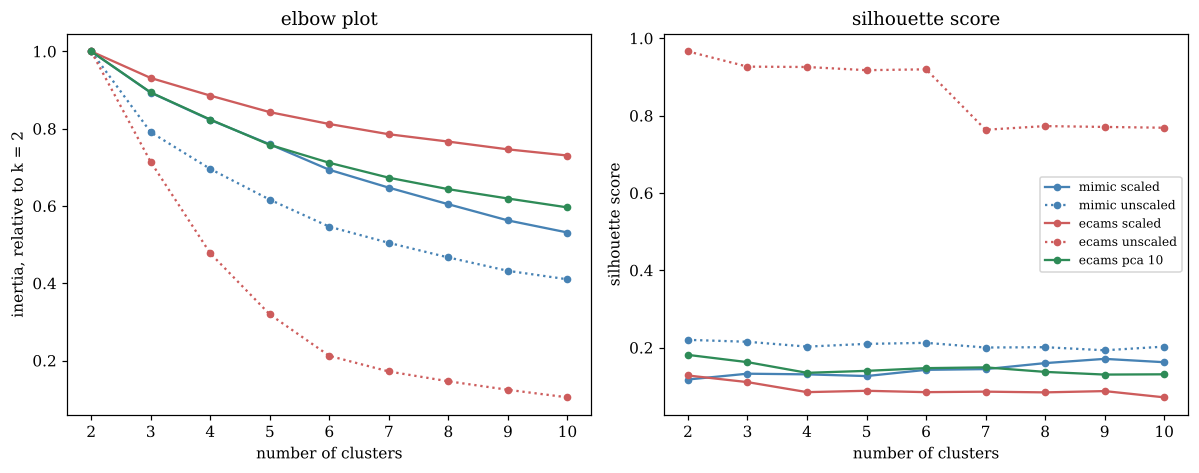

In [4]:
# figure, elbow on the left and silhouette on the right
fig, ax = plt.subplots(1, 2, figsize = (11, 4.4))
sty = {'mimic scaled': ('steelblue', '-'), 'mimic unscaled': ('steelblue', ':'), 'ecams scaled': ('indianred', '-'), 'ecams unscaled': ('indianred', ':'), 'ecams pca 10': ('seagreen', '-')}
for sp, (c, ls) in sty.items():
    t = ks_tab[ks_tab.space == sp]
    ax[0].plot(t['k'], t['inertia'] / t['inertia'].iloc[0], 'o', color = c, linestyle = ls, label = sp, markersize = 4)
    ax[1].plot(t['k'], t['silhouette'], 'o', color = c, linestyle = ls, label = sp, markersize = 4)
ax[0].set_xlabel('number of clusters')
ax[0].set_ylabel('inertia, relative to k = 2')
ax[0].set_title('elbow plot')
ax[1].set_xlabel('number of clusters')
ax[1].set_ylabel('silhouette score')
ax[1].set_title('silhouette score')
ax[1].legend(fontsize = 8)
plt.tight_layout()
plt.savefig('figs/w10_elbow_sil.png', dpi = 200)
plt.show()

The elbow plot isn't much use. Inertia falls smoothly in every space with no bend, so the elbow gives no answer for k. The silhouette gives answers, but they are weak ones. Scaled MIMIC is highest at k of 9 (0.171) with a flat stretch from 6 to 10 and ECAMS is best at k of 2 in both the scaled (0.128) and PCA (0.181) versions.

In [5]:
# what scaling does, the feature that dominates the distance in the unscaled spaces
for nm, X in [('mimic', Xm), ('ecams', Xe)]:
    v = X.var()
    print(nm, 'share of total variance from the biggest feature:', round(v.max() / v.sum(), 3), v.idxmax())
    print(nm, 'features that make up 95 percent of the variance:', int((v.sort_values(ascending = False).cumsum() / v.sum() < 0.95).sum()) + 1, 'of', X.shape[1])

mimic share of total variance from the biggest feature: 0.31 sbp
mimic features that make up 95 percent of the variance: 5 of 9
ecams share of total variance from the biggest feature: 0.213 max_ratio_psd_db_deltathetaValphabetamid'
ecams features that make up 95 percent of the variance: 18 of 1189


This is why the unscaled numbers look so different. On MIMIC systolic pressure alone is 31 percent of the total variance and 5 of 9 features make up 95 percent. On ECAMS it's far more extreme, 18 of the 1189 features carry 95 percent of the variance.

In [6]:
# the unscaled spaces, cluster sizes at k = 2 and what the silhouette is really rewarding
for sp, nm in [('mimic unscaled', 'mimic'), ('ecams unscaled', 'ecams')]:
    km = KMeans(n_clusters = 2, n_init = 20, random_state = 0).fit(spaces[sp])
    sizes = np.bincount(km.labels_)
    print(sp, 'cluster sizes', sizes.tolist(), 'silhouette', round(silhouette_score(spaces[sp], km.labels_), 3), 'ari with delirium', round(adjusted_rand_score(labels[nm], km.labels_), 3))
Zu = Xe.values
d = pd.Series(np.abs(Zu - Zu.mean(axis = 0)).mean(axis = 0), index = Xe.columns).sort_values(ascending = False)
print('ecams unscaled, the 3 features with the largest average spread:', d.head(3).round(0).to_dict())

mimic unscaled cluster sizes [50, 90] silhouette 0.22 ari with delirium -0.016
ecams unscaled cluster sizes [372, 1] silhouette 0.966 ari with delirium 0.006
ecams unscaled, the 3 features with the largest average spread: {"min_ratio_psd_db_deltathetamidVtheta'": 3392.0, "max_ratio_psd_db_deltathetaValphabetamid'": 3258.0, "max_ratio_psd_db_deltathetaValphalow'": 3243.0}


The 0.966 silhouette for unscaled ECAMS isn't a good clustering, it's one cluster of 372 patients and one patient on their own. The scales are so uneven that a single EEG ratio feature (the largest average spread is about 3400) pulls one outlier away from everyone. The silhouette is rewarding that. Unscaled MIMIC splits 50 and 90 with a silhouette of 0.22 and has an ARI with delirium of negative 0.016, so that structure has nothing to do with delirium. This is the main thing I'd warn about when using silhouette, a high score can come from a degenerate or scale driven solution.

In [7]:
# silhouette under different distance metrics for the same k means labels, and seed stability
rows = []
for sp in ['mimic scaled', 'ecams scaled', 'ecams pca 10']:
    Z = spaces[sp]
    for k in [2, 3, 4, 5]:
        km = KMeans(n_clusters = k, n_init = 20, random_state = 0).fit(Z)
        row = {'space': sp, 'k': k}
        for met in ['euclidean', 'manhattan', 'cosine']:
            row[met] = silhouette_score(Z, km.labels_, metric = met)
        runs = [KMeans(n_clusters = k, n_init = 1, random_state = s).fit(Z).labels_ for s in range(10)]
        aris = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
        row['seed ari mean'] = np.mean(aris)
        row['seed ari min'] = np.min(aris)
        rows.append(row)
metric_tab = pd.DataFrame(rows)
metric_tab.to_csv('figs/w10_metrics_seeds.csv', index = False)
metric_tab.round(3)

,space,k,euclidean,manhattan,cosine,seed ari mean,seed ari min
0,mimic scaled,2,0.118,0.124,0.216,0.176,-0.005
1,mimic scaled,3,0.133,0.147,0.245,0.363,0.027
2,mimic scaled,4,0.131,0.132,0.250,0.299,0.158
3,mimic scaled,5,0.126,0.137,0.133,0.375,0.187
4,ecams scaled,2,0.128,0.155,0.238,0.935,0.875
5,ecams scaled,3,0.111,0.132,0.202,0.701,0.420
6,ecams scaled,4,0.085,0.108,0.164,0.471,0.322
7,ecams scaled,5,0.088,0.108,0.166,0.472,0.320
8,ecams pca 10,2,0.181,0.151,0.322,0.941,0.875
9,ecams pca 10,3,0.162,0.130,0.281,0.670,0.351


Distance metric changes the silhouette more than I expected. For the same K means labels, cosine silhouette is nearly double the euclidean one (scaled MIMIC at k of 3 is 0.245 against 0.133, scaled ECAMS at k of 2 is 0.238 against 0.128, the PCA space is 0.322 against 0.181). K means itself minimizes euclidean distance, so the cosine version isn't a fair measure of what the algorithm optimized, but it does say the clusters are more separated by direction than by distance. The seed check shows how unstable some of these are. On ECAMS k of 2 the ten single start runs agree almost perfectly (mean ARI 0.935, worst pair 0.875) and at k of 4 they fall to 0.47. On MIMIC even k of 2 only agrees at 0.18 on average (worst pair about 0) which means a single start would give a different answer each time.

In [8]:
# spherical k means, normalize every row to length one first so the clusters follow direction and not size
rows = []
for sp in ['mimic scaled', 'ecams scaled']:
    Z = normalize(spaces[sp])
    for k in [2, 3, 4, 5, 6]:
        km = KMeans(n_clusters = k, n_init = 20, random_state = 0).fit(Z)
        rows.append({'space': sp + ', row normalized', 'k': k, 'silhouette cosine': silhouette_score(Z, km.labels_, metric = 'cosine'), 'ari with delirium': adjusted_rand_score(labels[sp.split()[0]], km.labels_)})
pd.DataFrame(rows).round(3)

,space,k,silhouette cosine,ari with delirium
0,"mimic scaled, row normalized",2,0.241,0.118
1,"mimic scaled, row normalized",3,0.255,0.028
2,"mimic scaled, row normalized",4,0.266,0.013
3,"mimic scaled, row normalized",5,0.257,0.015
4,"mimic scaled, row normalized",6,0.286,0.011
5,"ecams scaled, row normalized",2,0.238,0.218
6,"ecams scaled, row normalized",3,0.203,0.107
7,"ecams scaled, row normalized",4,0.187,0.115
8,"ecams scaled, row normalized",5,0.183,0.066
9,"ecams scaled, row normalized",6,0.166,0.068


Normalizing the rows to length one first (so K means follows direction, like cosine distance) gives silhouettes of 0.24 to 0.29 on MIMIC and 0.17 to 0.24 on ECAMS, a little better than plain euclidean but still low. The ARI with delirium stays small on MIMIC (0.01 to 0.12) and reaches 0.218 on ECAMS at k of 2.

In [9]:
# cluster profiles at the silhouette best k and at k = 4, delirium rate and size in every cluster
rows = []
for sp, nm in [('mimic scaled', 'mimic'), ('ecams scaled', 'ecams'), ('ecams pca 10', 'ecams')]:
    sub = ks_tab[ks_tab.space == sp]
    kbest = int(sub.loc[sub['silhouette'].idxmax(), 'k'])
    for k in sorted({kbest, 4}):
        km = KMeans(n_clusters = k, n_init = 20, random_state = 0).fit(spaces[sp])
        for c in range(k):
            mk = km.labels_ == c
            rows.append({'space': sp, 'k': k, 'cluster': c, 'size': int(mk.sum()), 'delirium rate': labels[nm][mk].mean(), 'ari with delirium': adjusted_rand_score(labels[nm], km.labels_)})
prof = pd.DataFrame(rows)
prof.to_csv('figs/w10_profiles.csv', index = False)
prof.round(3)

,space,k,cluster,size,delirium rate,ari with delirium
0,mimic scaled,4,0,39,0.256,-0.003
1,mimic scaled,4,1,28,0.321,-0.003
2,mimic scaled,4,2,40,0.400,-0.003
3,mimic scaled,4,3,33,0.303,-0.003
4,mimic scaled,9,0,22,0.364,0.020
5,mimic scaled,9,1,16,0.062,0.020
6,mimic scaled,9,2,20,0.200,0.020
7,mimic scaled,9,3,25,0.320,0.020
8,mimic scaled,9,4,14,0.214,0.020
9,mimic scaled,9,5,1,0.000,0.020


On ECAMS the two cluster solution splits the patients into 184 with a delirium rate of 92.4 percent and 189 with 44.4 percent. The adjusted Rand index against delirium is 0.22, which is low in absolute terms, but a gap between 92 and 44 percent from clustering that never saw the label is a real finding. The 10 component version gives the same split. At k of 4 the rates range from 33 to 97 percent. On MIMIC none of it lines up with delirium, at k of 4 the rates are 26, 32, 40 and 30 percent and the ARI is about zero. The k of 9 solution has rates from 6 to 65 percent but the clusters have 11 to 25 stays each so those differences could easily be noise.

In [10]:
# what the mimic clusters look like in the original units
km = KMeans(n_clusters = 3, n_init = 20, random_state = 0).fit(spaces['mimic scaled'])
tab = pd.DataFrame(Xm_filled, columns = mcols)
tab['cluster'] = km.labels_
tab['delirium'] = ym.values
tab.groupby('cluster').agg(['mean']).round(2).T

,cluster,0,1,2
anchor_age,mean,60.24,58.05,66.51
gender,mean,0.49,0.86,0.35
heart_rate,mean,81.44,90.17,92.84
sbp,mean,132.23,115.47,108.72
dbp,mean,72.93,61.92,59.37
resp_rate,mean,17.46,19.47,21.26
temp_f,mean,98.32,98.72,98.26
spo2,mean,96.70,97.16,96.25
gcs_total_min,mean,12.71,3.68,11.98
delirium,mean,0.24,0.43,0.29


The three MIMIC clusters (41, 44 and 55 stays) are split mostly by GCS and blood pressure. Cluster 1 has an average minimum GCS of 3.7 against about 12 to 13 in the others, it's 86 percent male and has the highest delirium rate at 43 percent. Cluster 0 has the highest blood pressure (systolic 132) and the lowest delirium rate at 24 percent, cluster 2 is the oldest group (66.5) with the lowest blood pressure and a rate of 29 percent. So the clusters do pick up clinically sensible groups, comatose patients, hypertensive patients and older hypotensive patients, but the delirium rates only differ by 24 to 43 percent on groups of 40 to 55 stays.

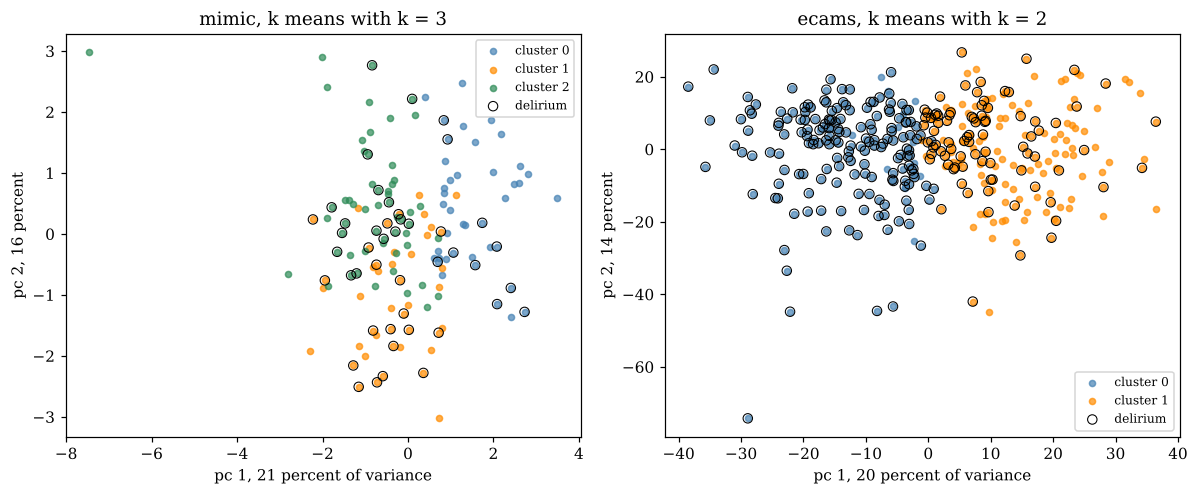

In [11]:
# figure, clusters in the first two principal components, colored by cluster and outlined by delirium
fig, ax = plt.subplots(1, 2, figsize = (11, 4.6))
for i, (sp, nm, k) in enumerate([('mimic scaled', 'mimic', 3), ('ecams scaled', 'ecams', 2)]):
    Z = spaces[sp]
    km = KMeans(n_clusters = k, n_init = 20, random_state = 0).fit(Z)
    pc = PCA(2, random_state = 0).fit(Z)
    P = pc.transform(Z)
    pal = ['steelblue', 'darkorange', 'seagreen', 'purple']
    for c in range(k):
        mk = km.labels_ == c
        ax[i].scatter(P[mk, 0], P[mk, 1], s = 16, color = pal[c], alpha = 0.7, label = 'cluster ' + str(c))
    pos = labels[nm] == 1
    ax[i].scatter(P[pos, 0], P[pos, 1], s = 38, facecolors = 'none', edgecolors = 'black', linewidths = 0.7, label = 'delirium')
    ax[i].set_xlabel('pc 1, ' + str(round(pc.explained_variance_ratio_[0] * 100)) + ' percent of variance')
    ax[i].set_ylabel('pc 2, ' + str(round(pc.explained_variance_ratio_[1] * 100)) + ' percent')
    ax[i].set_title(nm + ', k means with k = ' + str(k))
    ax[i].legend(fontsize = 8)
plt.tight_layout()
plt.savefig('figs/w10_pca_clusters.png', dpi = 200)
plt.show()

The principal component plots show why the silhouettes are low. The MIMIC clusters overlap in the middle and the delirium points are scattered through all three. ECAMS has a clear left to right gradient and the two clusters are more like two halves of one cloud than two separate groups, although the delirium points are noticeably denser in the blue half, the one with 184 patients.

To sum up, silhouette said k of 2 for ECAMS and nothing clear for MIMIC, scaling is required, and the ECAMS split lines up with delirium better than I expected for an unsupervised method.